In [ ]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
import os

folder = "/content/drive/MyDrive/Nouriva-AI"

print("Folder exists:", os.path.exists(folder))

if os.path.exists(folder):
    print("Files:", os.listdir(folder))

Folder exists: True
Files: ['THFOOD10.zip']


In [ ]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

CUDA available: True
GPU: Tesla T4


In [ ]:
from pathlib import Path

root = Path("/content/data")

print("=== โฟลเดอร์ที่พบ ===")
for path in root.rglob("train"):
    if path.is_dir():
        print("TRAIN:", path)
        print("VAL:", path.parent / "val")

=== โฟลเดอร์ที่พบ ===


In [ ]:
from pathlib import Path

dataset_path = Path("/content/data/THFOOD10/THFOOD10")

print("Train exists:", (dataset_path / "train").is_dir())
print("Val exists:", (dataset_path / "val").is_dir())

Train exists: False
Val exists: False


In [ ]:
from pathlib import Path

root = Path("/content/data")

print("=== โครงสร้างโฟลเดอร์ ===")

for p in root.iterdir():
    print(p.name)

print("\n=== ค้นหา train และ val ===")

for p in root.rglob("*"):
    if p.is_dir() and p.name.lower() == "train":
        print("พบ TRAIN:", p)
        print("มี VAL คู่กัน:", (p.parent / "val").is_dir())

=== โครงสร้างโฟลเดอร์ ===
THFOOD10\val\Somtam\2365.jpg
THFOOD10\train\PhatKaphrao\2085.jpg
THFOOD10\train\StewedPorkLeg\2715.jpg
THFOOD10\train\FriedChicken\6.jpg
THFOOD10\train\GaengKeawWan\655.jpg
THFOOD10\train\FriedChicken\15.jpg
THFOOD10\train\KhaoNiewMaMuang\170.jpg
THFOOD10\train\PadThai\1670.jpg
THFOOD10\train\KuayTeowReua\393.jpg
THFOOD10\train\KaoManGai\883.jpg
THFOOD10\train\FriedChicken\54.jpg
THFOOD10\train\KuayTeowReua\201.jpg
THFOOD10\train\StewedPorkLeg\2688.jpg
THFOOD10\train\StewedPorkLeg\2541.jpg
THFOOD10\train\KhaoNiewMaMuang\192.jpg
THFOOD10\train\KhaoNiewMaMuang\129.jpg
THFOOD10\train\TomYumGoong\3109.jpg
THFOOD10\train\PadThai\1707.jpg
THFOOD10\train\TomYumGoong\3064.jpg
THFOOD10\train\KaoManGai\921.jpg
THFOOD10\train\KhaoNiewMaMuang\394.jpg
THFOOD10\train\FriedChicken\312.jpg
THFOOD10\val\FriedChicken\86.jpg
THFOOD10\train\StewedPorkLeg\2563.jpg
THFOOD10\train\KaoManGai\853.jpg
THFOOD10\train\StewedPorkLeg\2654.jpg
THFOOD10\train\PadThai\1875.jpg
THFOOD10\train\

In [ ]:
from pathlib import Path

root = Path("/content/data")

candidates = [
    p.parent
    for p in root.rglob("*")
    if p.is_dir()
    and p.name.lower() == "train"
    and (p.parent / "val").is_dir()
]

if not candidates:
    raise FileNotFoundError(
        "ยังไม่พบโฟลเดอร์ train และ val กรุณาส่งผลขั้นตอนที่ 1"
    )

dataset_path = candidates[0]

print("Dataset ready:", dataset_path)
print("Train exists:", (dataset_path / "train").is_dir())
print("Val exists:", (dataset_path / "val").is_dir())

FileNotFoundError: ยังไม่พบโฟลเดอร์ train และ val กรุณาส่งผลขั้นตอนที่ 1

In [ ]:

from pathlib import Path
import zipfile
import shutil

zip_path = Path("/content/drive/MyDrive/Nouriva-AI/THFOOD10.zip")
extract_to = Path("/content/THFOOD10_fixed")
extract_to.mkdir(parents=True, exist_ok=True)

# แตกไฟล์โดยเปลี่ยนเครื่องหมาย \ ของ Windows เป็น /
with zipfile.ZipFile(zip_path, "r") as z:
    for item in z.infolist():
        name = item.filename.replace("\\", "/")
        parts = Path(name).parts

        # ป้องกันเส้นทางที่ไม่ปลอดภัย
        if not parts or ".." in parts or name.startswith("/"):
            continue

        target = extract_to.joinpath(*parts)

        if item.is_dir() or name.endswith("/"):
            target.mkdir(parents=True, exist_ok=True)
        else:
            target.parent.mkdir(parents=True, exist_ok=True)
            with z.open(item) as src, open(target, "wb") as dst:
                shutil.copyfileobj(src, dst)

# ค้นหาโฟลเดอร์ train และ val
candidates = [
    p.parent for p in extract_to.rglob("train")
    if p.is_dir() and (p.parent / "val").is_dir()
]

assert candidates, "ไม่พบ train และ val หลังแตกไฟล์"

dataset_path = candidates[0]

print("Dataset ready:", dataset_path)

for split in ["train", "val"]:
    images = [
        p for p in (dataset_path / split).rglob("*")
        if p.is_file()
        and p.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"}
    ]
    classes = [
        p for p in (dataset_path / split).iterdir()
        if p.is_dir()
    ]
    print(f"{split}: {len(images)} images, {len(classes)} classes")


Dataset ready: /content/THFOOD10_fixed/THFOOD10
train: 2564 images, 10 classes
val: 290 images, 10 classes


In [ ]:

from pathlib import Path
from collections import Counter
import hashlib

dataset_path = Path("/content/THFOOD10_fixed/THFOOD10")
extensions = {".jpg", ".jpeg", ".png", ".webp"}

train_dir = dataset_path / "train"
val_dir = dataset_path / "val"

train_classes = sorted(p.name for p in train_dir.iterdir() if p.is_dir())
val_classes = sorted(p.name for p in val_dir.iterdir() if p.is_dir())

assert train_classes == val_classes, "Train และ Val มีคลาสไม่ตรงกัน"
assert len(train_classes) == 10, "จำนวนคลาสไม่เท่ากับ 10"

print("=== รายชื่อคลาส ===")
for i, name in enumerate(train_classes):
    print(i, name)

def get_images(folder):
    return sorted(
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in extensions
    )

train_images = get_images(train_dir)
val_images = get_images(val_dir)

def file_hash(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

train_hashes = {file_hash(p) for p in train_images}
val_hashes = {file_hash(p) for p in val_images}

print("\n=== ตรวจสอบ Dataset ===")
print("Train:", len(train_images))
print("Validation:", len(val_images))
print("ภาพซ้ำแบบไฟล์เหมือนกันข้าม Train/Val:",
      len(train_hashes & val_hashes))

print("พร้อมสำหรับขั้นตอนถัดไป")


=== รายชื่อคลาส ===
0 FriedChicken
1 GaengKeawWan
2 KaoManGai
3 KhaoNiewMaMuang
4 KuayTeowReua
5 PadThai
6 PhatKaphrao
7 Somtam
8 StewedPorkLeg
9 TomYumGoong

=== ตรวจสอบ Dataset ===
Train: 2564
Validation: 290
ภาพซ้ำแบบไฟล์เหมือนกันข้าม Train/Val: 0
พร้อมสำหรับขั้นตอนถัดไป


In [ ]:

import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from pathlib import Path

dataset_path = Path("/content/THFOOD10_fixed/THFOOD10")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# การแปลงภาพสำหรับฝึก
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.75, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Validation ไม่สุ่มเปลี่ยนภาพ
val_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

train_dataset = datasets.ImageFolder(
    dataset_path / "train",
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    dataset_path / "val",
    transform=val_transform
)

assert train_dataset.class_to_idx == val_dataset.class_to_idx

train_loader = DataLoader(
    train_dataset, batch_size=32,
    shuffle=True, num_workers=2, pin_memory=True
)

val_loader = DataLoader(
    val_dataset, batch_size=32,
    shuffle=False, num_workers=2, pin_memory=True
)

class_names = train_dataset.classes

print("Device:", device)
print("Train images:", len(train_dataset))
print("Val images:", len(val_dataset))
print("Classes:", class_names)


Device: cuda
Train images: 2564
Val images: 290
Classes: ['FriedChicken', 'GaengKeawWan', 'KaoManGai', 'KhaoNiewMaMuang', 'KuayTeowReua', 'PadThai', 'PhatKaphrao', 'Somtam', 'StewedPorkLeg', 'TomYumGoong']


In [ ]:

import torch.nn as nn
from torchvision.models import (
    efficientnet_b0,
    EfficientNet_B0_Weights
)

weights = EfficientNet_B0_Weights.DEFAULT
model = efficientnet_b0(weights=weights)

# ฝึกเฉพาะชั้น classifier ในรอบแรก
for param in model.features.parameters():
    param.requires_grad = False

num_features = model.classifier[1].in_features

model.classifier[1] = nn.Linear(
    num_features, len(class_names)
)

model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(
    model.classifier.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

print("Model ready: EfficientNet-B0")
print("Output classes:", len(class_names))


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 49.7MB/s]


Model ready: EfficientNet-B0
Output classes: 10


Epoch 1/10 | Train Acc: 0.7718 | Val Acc: 0.9172 | Val Loss: 0.4672
  ✓ Saved best_model.pth
Epoch 2/10 | Train Acc: 0.9271 | Val Acc: 0.9310 | Val Loss: 0.3176
  ✓ Saved best_model.pth
Epoch 3/10 | Train Acc: 0.9501 | Val Acc: 0.9414 | Val Loss: 0.2574
  ✓ Saved best_model.pth
Epoch 4/10 | Train Acc: 0.9606 | Val Acc: 0.9379 | Val Loss: 0.2317
Epoch 5/10 | Train Acc: 0.9626 | Val Acc: 0.9379 | Val Loss: 0.2008
Epoch 6/10 | Train Acc: 0.9704 | Val Acc: 0.9345 | Val Loss: 0.1944
Early stopping

Training complete!
Best validation accuracy: 94.14%
Saved to: /content/drive/MyDrive/Nouriva-AI/models


=== Classification Report ===
                 precision    recall  f1-score   support

   FriedChicken     1.0000    1.0000    1.0000        34
   GaengKeawWan     1.0000    0.7500    0.8571        20
      KaoManGai     0.9167    0.9167    0.9167        24
KhaoNiewMaMuang     1.0000    0.9825    0.9912        57
   KuayTeowReua     0.8723    0.9535    0.9111        43
        PadThai     0.9583    0.9583    0.9583        24
    PhatKaphrao     1.0000    0.9524    0.9756        21
         Somtam     1.0000    0.8636    0.9268        22
  StewedPorkLeg     0.8846    0.9583    0.9200        24
    TomYumGoong     0.8000    0.9524    0.8696        21

       accuracy                         0.9414       290
      macro avg     0.9432    0.9288    0.9326       290
   weighted avg     0.9467    0.9414    0.9415       290



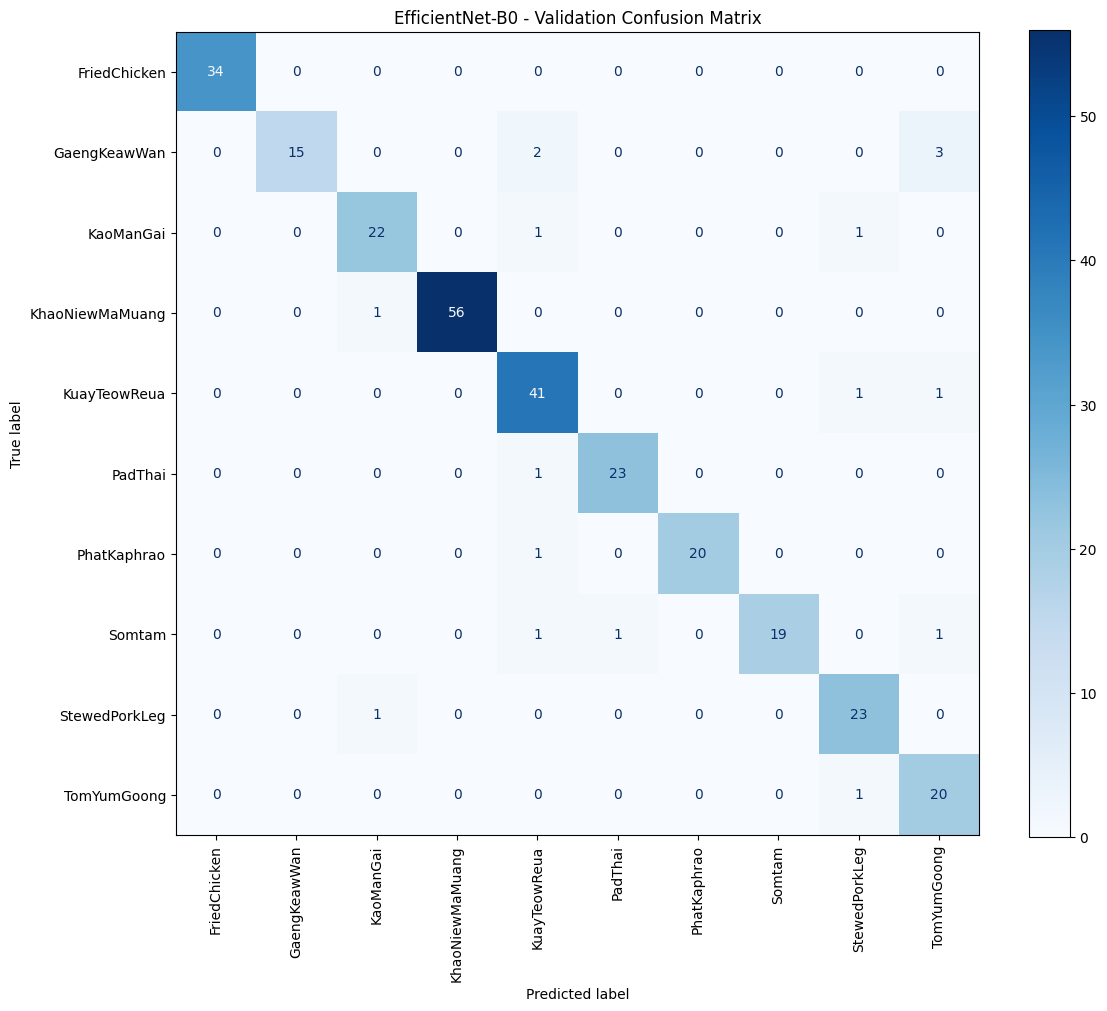

In [ ]:

import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from pathlib import Path

model_path = Path(
    "/content/drive/MyDrive/Nouriva-AI/models/best_model.pth"
)

checkpoint = torch.load(
    model_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1).cpu().numpy()

        y_true.extend(labels.numpy())
        y_pred.extend(predictions)

print("=== Classification Report ===")
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4,
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(12, 10))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)
disp.plot(ax=ax, cmap="Blues", xticks_rotation=90)

plt.title("EfficientNet-B0 - Validation Confusion Matrix")
plt.tight_layout()
plt.show()


In [ ]:

from pathlib import Path
import zipfile
import hashlib
import shutil
import csv

zip_path = Path("/content/drive/MyDrive/Nouriva-AI/test_200.zip")
test_dir = Path("/content/test_200")
dataset_path = Path("/content/THFOOD10_fixed/THFOOD10")

assert zip_path.is_file(), "ไม่พบ test_200.zip ใน Google Drive"

# แตกไฟล์ Test 200 ภาพ
with zipfile.ZipFile(zip_path) as z:
    for item in z.infolist():
        name = item.filename.replace("\\", "/")
        parts = Path(name).parts
        if not parts or ".." in parts or name.startswith("/"):
            continue

        target = test_dir.joinpath(*parts)
        if item.is_dir():
            target.mkdir(parents=True, exist_ok=True)
        else:
            target.parent.mkdir(parents=True, exist_ok=True)
            with z.open(item) as src, open(target, "wb") as dst:
                shutil.copyfileobj(src, dst)

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

extensions = {".jpg", ".jpeg", ".png", ".webp"}

train_val_images = [
    p for p in dataset_path.rglob("*")
    if p.is_file() and p.suffix.lower() in extensions
]

with open(test_dir / "ground_truth.csv",
          encoding="utf-8-sig", newline="") as f:
    records = list(csv.DictReader(f))

test_images = [
    test_dir / row["image_path"]
    for row in records
]

assert len(test_images) == 200
assert all(p.is_file() for p in test_images), "พบภาพ Test ที่หายไป"

known_hashes = {sha256(p) for p in train_val_images}

duplicates = [
    str(p) for p in test_images
    if sha256(p) in known_hashes
]

print("Train + Val:", len(train_val_images))
print("Test:", len(test_images))
print("ภาพ Test ที่ไฟล์ซ้ำกับ Train/Val:", len(duplicates))

if duplicates:
    print("ตัวอย่างภาพซ้ำ:", duplicates[:10])
    print("ต้องจัดการภาพซ้ำก่อนประเมินผล")
else:
    print("ไม่พบไฟล์ซ้ำแบบ SHA-256")
    print("ขั้นต่อไป: ตรวจภาพที่คล้ายกันหรือมาจากต้นฉบับเดียวกัน")


Train + Val: 2854
Test: 200
ภาพ Test ที่ไฟล์ซ้ำกับ Train/Val: 0
ไม่พบไฟล์ซ้ำแบบ SHA-256
ขั้นต่อไป: ตรวจภาพที่คล้ายกันหรือมาจากต้นฉบับเดียวกัน


In [ ]:

!pip -q install ImageHash

from PIL import Image
import imagehash
import csv
from pathlib import Path

# ใช้ตัวแปรจากเซลล์ที่ตรวจ SHA-256 ก่อนหน้านี้:
# train_val_images, test_images, dataset_path, test_dir

def get_phash(path):
    try:
        with Image.open(path) as img:
            return imagehash.phash(img.convert("RGB"))
    except Exception as e:
        print("อ่านภาพไม่ได้:", path, e)
        return None

print("กำลังคำนวณ pHash ของภาพ Train/Val...")
reference = []
for path in train_val_images:
    h = get_phash(path)
    if h is not None:
        reference.append((path, h))

print("กำลังเปรียบเทียบ Test 200 ภาพ...")

# pHash ระยะน้อย = ภาพมีโครงสร้างโดยรวมคล้ายกัน
# เกณฑ์ <= 5 เป็นเพียงตัวคัดกรอง ไม่ใช่ข้อสรุปว่าซ้ำ
suspects = []

for test_path in test_images:
    test_hash = get_phash(test_path)
    if test_hash is None:
        continue

    matches = sorted(
        (
            (test_hash - ref_hash, ref_path)
            for ref_path, ref_hash in reference
        ),
        key=lambda x: x[0]
    )

    distance, closest_path = matches[0]

    if distance <= 5:
        suspects.append({
            "test_image": str(test_path),
            "closest_train_val": str(closest_path),
            "phash_distance": distance
        })

report_path = Path("/content/phash_suspects.csv")

with open(report_path, "w", newline="", encoding="utf-8-sig") as f:
    writer = csv.DictWriter(
        f,
        fieldnames=[
            "test_image",
            "closest_train_val",
            "phash_distance"
        ]
    )
    writer.writeheader()
    writer.writerows(suspects)

print("\n=== ผลตรวจภาพคล้าย ===")
print("Test images:", len(test_images))
print("Potential near-duplicates:", len(suspects))
print("Saved:", report_path)

for row in sorted(
    suspects,
    key=lambda r: r["phash_distance"]
)[:15]:
    print(
        "Distance:", row["phash_distance"],
        "| Test:", Path(row["test_image"]).name,
        "| Match:", Path(row["closest_train_val"]).name
    )


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 8.1 MB/s eta 0:00:00
กำลังคำนวณ pHash ของภาพ Train/Val...
กำลังเปรียบเทียบ Test 200 ภาพ...

=== ผลตรวจภาพคล้าย ===
Test images: 200
Potential near-duplicates: 21
Saved: /content/phash_suspects.csv
Distance: 0 | Test: 006.jpg | Match: 175.jpg
Distance: 0 | Test: 014.jpg | Match: 315.jpg
Distance: 0 | Test: 001.jpg | Match: 042.jpg
Distance: 0 | Test: 005.jpg | Match: 132.jpg
Distance: 0 | Test: 008.jpg | Match: 252.jpg
Distance: 0 | Test: 009.jpg | Match: 270.jpg
Distance: 0 | Test: 010.jpg | Match: 308.jpg
Distance: 0 | Test: 007.jpg | Match: 189.jpg
Distance: 0 | Test: 005.jpg | Match: 1750.jpg
Distance: 0 | Test: 014.jpg | Match: 2039.jpg
Distance: 0 | Test: 017.jpg | Match: 2097.jpg
Distance: 0 | Test: 005.jpg | Match: 2572.jpg
Distance: 0 | Test: 009.jpg | Match: 2624.jpg
Distance: 0 | Test: 013.jpg | Match: 2643.jpg
Distance: 0 | Test: 008.jpg | Match: 3126.jpg


จำนวนภาพที่ต้องตรวจ: 21


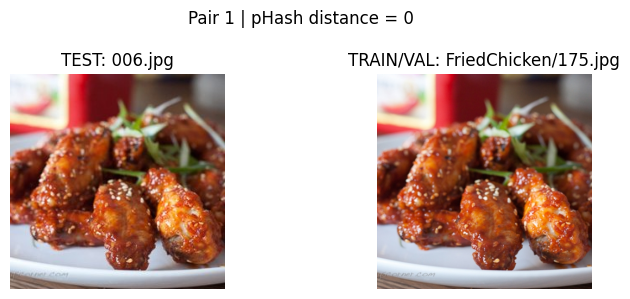

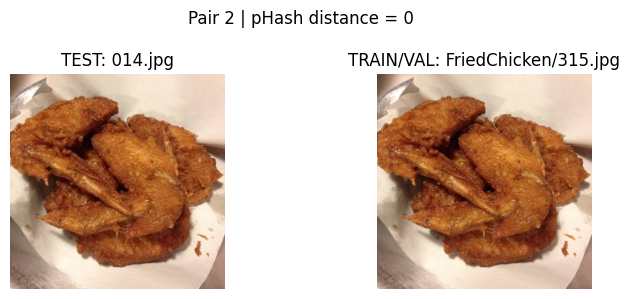

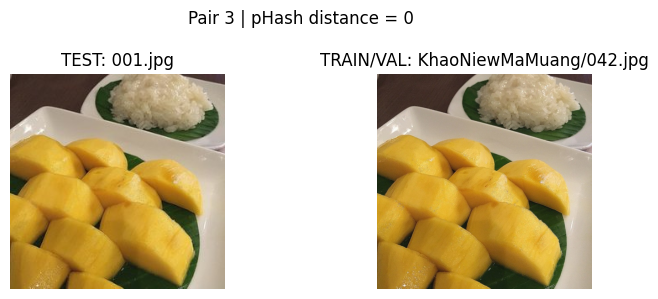

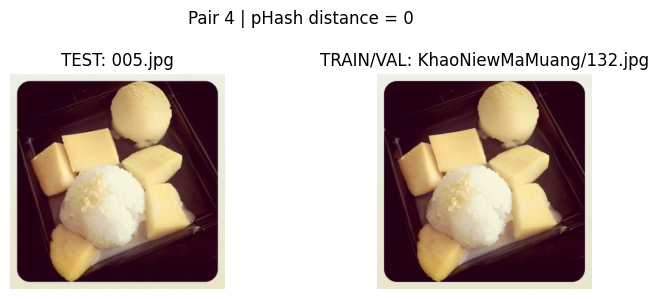

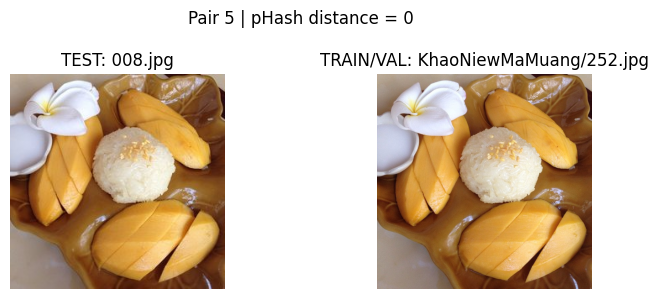

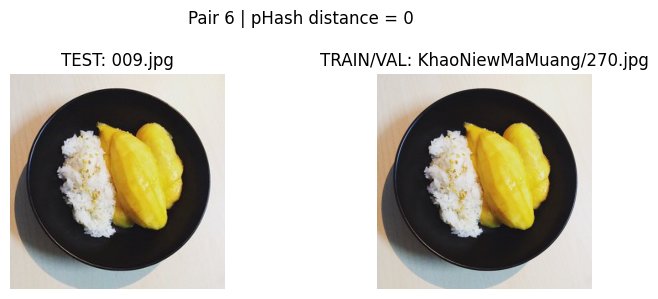

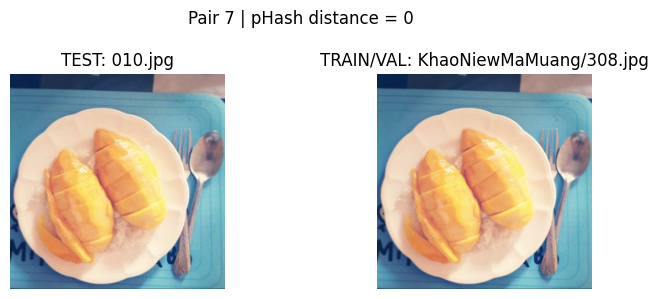

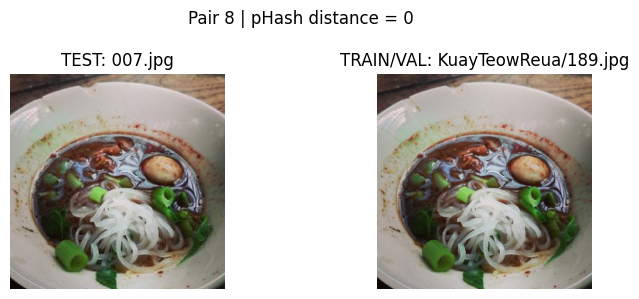

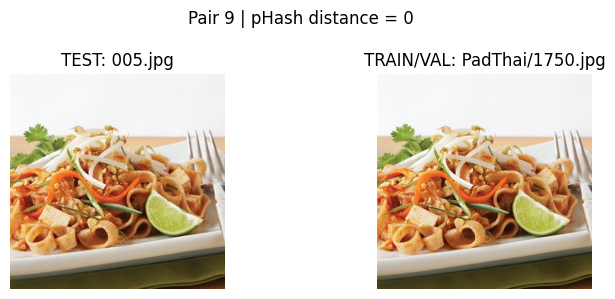

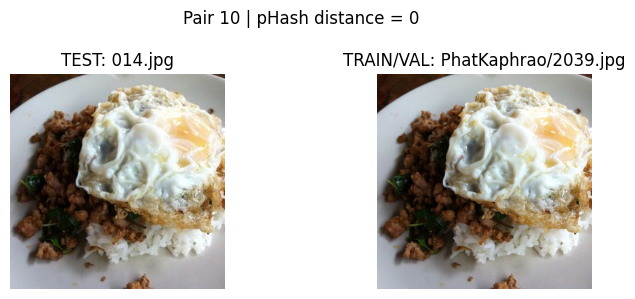

In [ ]:

import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

print("จำนวนภาพที่ต้องตรวจ:", len(suspects))

# แสดงภาพ Test คู่กับภาพ Train/Val ที่คล้ายที่สุด
for i, item in enumerate(
    sorted(suspects, key=lambda x: x["phash_distance"])[:10]
):
    test_path = Path(item["test_image"])
    match_path = Path(item["closest_train_val"])
    distance = item["phash_distance"]

    fig, axes = plt.subplots(1, 2, figsize=(8, 3))

    with Image.open(test_path) as img:
        axes[0].imshow(img.convert("RGB"))

    axes[0].set_title(f"TEST: {test_path.name}")
    axes[0].axis("off")

    with Image.open(match_path) as img:
        axes[1].imshow(img.convert("RGB"))

    axes[1].set_title(
        f"TRAIN/VAL: {match_path.parent.name}/{match_path.name}"
    )
    axes[1].axis("off")

    plt.suptitle(f"Pair {i+1} | pHash distance = {distance}")
    plt.tight_layout()
    plt.show()


In [ ]:

import torch
import pandas as pd
from PIL import Image
from pathlib import Path
from torchvision import transforms
from torchvision.models import efficientnet_b0
import torch.nn as nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model_path = Path(
    "/content/drive/MyDrive/Nouriva-AI/models/best_model.pth"
)

checkpoint = torch.load(
    model_path, map_location=device, weights_only=True
)

class_names = checkpoint["class_names"]

model = efficientnet_b0(weights=None)
model.classifier[1] = nn.Linear(
    model.classifier[1].in_features,
    len(class_names)
)
model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(device)
model.eval()

class_to_thai = {
    "FriedChicken": "ไก่ทอด",
    "GaengKeawWan": "แกงเขียวหวาน",
    "KaoManGai": "ข้าวมันไก่",
    "KhaoNiewMaMuang": "ข้าวเหนียวมะม่วง",
    "KuayTeowReua": "ก๋วยเตี๋ยวเรือ",
    "PadThai": "ผัดไทย",
    "PhatKaphrao": "ผัดกะเพรา",
    "Somtam": "ส้มตำ",
    "StewedPorkLeg": "ข้าวขาหมู",
    "TomYumGoong": "ต้มยำกุ้ง"
}

test_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

records = pd.read_csv(
    test_dir / "ground_truth.csv",
    encoding="utf-8-sig"
)

assert len(records) == 200
assert set(class_names) == set(class_to_thai)

results = []

with torch.inference_mode():
    for _, row in records.iterrows():
        image_path = test_dir / str(row["image_path"])

        with Image.open(image_path) as img:
            image = test_transform(
                img.convert("RGB")
            ).unsqueeze(0).to(device)

        logits = model(image)
        probabilities = torch.softmax(logits, dim=1)[0]

        pred_idx = int(probabilities.argmax().item())
        predicted_class = class_names[pred_idx]
        predicted_th = class_to_thai[predicted_class]
        ground_truth = str(row["ground_truth_th"]).strip()

        results.append({
            "image_path": row["image_path"],
            "ground_truth_th": ground_truth,
            "predicted_class": predicted_class,
            "predicted_th": predicted_th,
            "confidence": float(
                probabilities[pred_idx].item()
            ),
            "correct": int(predicted_th == ground_truth)
        })

results_df = pd.DataFrame(results)

save_dir = Path("/content/drive/MyDrive/Nouriva-AI/results")
save_dir.mkdir(parents=True, exist_ok=True)

output_path = save_dir / "efficientnet_predictions.csv"
results_df.to_csv(
    output_path, index=False, encoding="utf-8-sig"
)

print("Predictions:", len(results_df))
print("Correct:", results_df["correct"].sum())
print("Accuracy:", f'{results_df["correct"].mean():.2%}')
print("Saved:", output_path)

display(results_df.head(10))


Predictions: 200
Correct: 179
Accuracy: 89.50%
Saved: /content/drive/MyDrive/Nouriva-AI/results/efficientnet_predictions.csv


,image_path,ground_truth_th,predicted_class,predicted_th,confidence,correct
0,images/FriedChicken/001.jpg,ไก่ทอด,FriedChicken,ไก่ทอด,0.494913,1
1,images/FriedChicken/002.jpg,ไก่ทอด,FriedChicken,ไก่ทอด,0.942913,1
2,images/FriedChicken/003.jpg,ไก่ทอด,FriedChicken,ไก่ทอด,0.977994,1
3,images/FriedChicken/004.jpg,ไก่ทอด,FriedChicken,ไก่ทอด,0.973020,1
4,images/FriedChicken/005.jpg,ไก่ทอด,FriedChicken,ไก่ทอด,0.969976,1
5,images/FriedChicken/006.jpg,ไก่ทอด,FriedChicken,ไก่ทอด,0.894655,1
6,images/FriedChicken/007.jpg,ไก่ทอด,FriedChicken,ไก่ทอด,0.886747,1
7,images/FriedChicken/008.jpg,ไก่ทอด,FriedChicken,ไก่ทอด,0.663472,1
8,images/FriedChicken/009.jpg,ไก่ทอด,FriedChicken,ไก่ทอด,0.936098,1
9,images/FriedChicken/010.jpg,ไก่ทอด,FriedChicken,ไก่ทอด,0.844115,1


In [ ]:

import torch
import pandas as pd
from PIL import Image
from pathlib import Path
from torchvision import transforms
from torchvision.models import efficientnet_b0
import torch.nn as nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model_path = Path(
    "/content/drive/MyDrive/Nouriva-AI/models/best_model.pth"
)

checkpoint = torch.load(
    model_path, map_location=device, weights_only=True
)

class_names = checkpoint["class_names"]

model = efficientnet_b0(weights=None)
model.classifier[1] = nn.Linear(
    model.classifier[1].in_features,
    len(class_names)
)
model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(device)
model.eval()

class_to_thai = {
    "FriedChicken": "ไก่ทอด",
    "GaengKeawWan": "แกงเขียวหวาน",
    "KaoManGai": "ข้าวมันไก่",
    "KhaoNiewMaMuang": "ข้าวเหนียวมะม่วง",
    "KuayTeowReua": "ก๋วยเตี๋ยวเรือ",
    "PadThai": "ผัดไทย",
    "PhatKaphrao": "ผัดกะเพรา",
    "Somtam": "ส้มตำ",
    "StewedPorkLeg": "ข้าวขาหมู",
    "TomYumGoong": "ต้มยำกุ้ง"
}

test_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

records = pd.read_csv(
    test_dir / "ground_truth.csv",
    encoding="utf-8-sig"
)

assert len(records) == 200
assert set(class_names) == set(class_to_thai)

results = []

with torch.inference_mode():
    for _, row in records.iterrows():
        image_path = test_dir / str(row["image_path"])

        with Image.open(image_path) as img:
            image = test_transform(
                img.convert("RGB")
            ).unsqueeze(0).to(device)

        logits = model(image)
        probabilities = torch.softmax(logits, dim=1)[0]

        pred_idx = int(probabilities.argmax().item())
        predicted_class = class_names[pred_idx]
        predicted_th = class_to_thai[predicted_class]
        ground_truth = str(row["ground_truth_th"]).strip()

        results.append({
            "image_path": row["image_path"],
            "ground_truth_th": ground_truth,
            "predicted_class": predicted_class,
            "predicted_th": predicted_th,
            "confidence": float(
                probabilities[pred_idx].item()
            ),
            "correct": int(predicted_th == ground_truth)
        })

results_df = pd.DataFrame(results)

save_dir = Path("/content/drive/MyDrive/Nouriva-AI/results")
save_dir.mkdir(parents=True, exist_ok=True)

output_path = save_dir / "efficientnet_predictions.csv"
results_df.to_csv(
    output_path, index=False, encoding="utf-8-sig"
)

print("Predictions:", len(results_df))
print("Correct:", results_df["correct"].sum())
print("Accuracy:", f'{results_df["correct"].mean():.2%}')
print("Saved:", output_path)

display(results_df.head(10))


Predictions: 200
Correct: 179
Accuracy: 89.50%
Saved: /content/drive/MyDrive/Nouriva-AI/results/efficientnet_predictions.csv


,image_path,ground_truth_th,predicted_class,predicted_th,confidence,correct
0,images/FriedChicken/001.jpg,ไก่ทอด,FriedChicken,ไก่ทอด,0.494913,1
1,images/FriedChicken/002.jpg,ไก่ทอด,FriedChicken,ไก่ทอด,0.942913,1
2,images/FriedChicken/003.jpg,ไก่ทอด,FriedChicken,ไก่ทอด,0.977994,1
3,images/FriedChicken/004.jpg,ไก่ทอด,FriedChicken,ไก่ทอด,0.973020,1
4,images/FriedChicken/005.jpg,ไก่ทอด,FriedChicken,ไก่ทอด,0.969976,1
5,images/FriedChicken/006.jpg,ไก่ทอด,FriedChicken,ไก่ทอด,0.894655,1
6,images/FriedChicken/007.jpg,ไก่ทอด,FriedChicken,ไก่ทอด,0.886747,1
7,images/FriedChicken/008.jpg,ไก่ทอด,FriedChicken,ไก่ทอด,0.663472,1
8,images/FriedChicken/009.jpg,ไก่ทอด,FriedChicken,ไก่ทอด,0.936098,1
9,images/FriedChicken/010.jpg,ไก่ทอด,FriedChicken,ไก่ทอด,0.844115,1


In [ ]:

import torch
import pandas as pd
from PIL import Image
from pathlib import Path
from torchvision import transforms
from torchvision.models import efficientnet_b0
import torch.nn as nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model_path = Path(
    "/content/drive/MyDrive/Nouriva-AI/models/best_model.pth"
)

checkpoint = torch.load(
    model_path, map_location=device, weights_only=True
)

class_names = checkpoint["class_names"]

model = efficientnet_b0(weights=None)
model.classifier[1] = nn.Linear(
    model.classifier[1].in_features,
    len(class_names)
)
model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(device)
model.eval()

class_to_thai = {
    "FriedChicken": "ไก่ทอด",
    "GaengKeawWan": "แกงเขียวหวาน",
    "KaoManGai": "ข้าวมันไก่",
    "KhaoNiewMaMuang": "ข้าวเหนียวมะม่วง",
    "KuayTeowReua": "ก๋วยเตี๋ยวเรือ",
    "PadThai": "ผัดไทย",
    "PhatKaphrao": "ผัดกะเพรา",
    "Somtam": "ส้มตำ",
    "StewedPorkLeg": "ข้าวขาหมู",
    "TomYumGoong": "ต้มยำกุ้ง"
}

test_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

records = pd.read_csv(
    test_dir / "ground_truth.csv",
    encoding="utf-8-sig"
)

assert len(records) == 200
assert set(class_names) == set(class_to_thai)

results = []

with torch.inference_mode():
    for _, row in records.iterrows():
        image_path = test_dir / str(row["image_path"])

        with Image.open(image_path) as img:
            image = test_transform(
                img.convert("RGB")
            ).unsqueeze(0).to(device)

        logits = model(image)
        probabilities = torch.softmax(logits, dim=1)[0]

        pred_idx = int(probabilities.argmax().item())
        predicted_class = class_names[pred_idx]
        predicted_th = class_to_thai[predicted_class]
        ground_truth = str(row["ground_truth_th"]).strip()

        results.append({
            "image_path": row["image_path"],
            "ground_truth_th": ground_truth,
            "predicted_class": predicted_class,
            "predicted_th": predicted_th,
            "confidence": float(
                probabilities[pred_idx].item()
            ),
            "correct": int(predicted_th == ground_truth)
        })

results_df = pd.DataFrame(results)

save_dir = Path("/content/drive/MyDrive/Nouriva-AI/results")
save_dir.mkdir(parents=True, exist_ok=True)

output_path = save_dir / "efficientnet_predictions.csv"
results_df.to_csv(
    output_path, index=False, encoding="utf-8-sig"
)

print("Predictions:", len(results_df))
print("Correct:", results_df["correct"].sum())
print("Accuracy:", f'{results_df["correct"].mean():.2%}')
print("Saved:", output_path)

display(results_df.head(10))


Predictions: 200
Correct: 179
Accuracy: 89.50%
Saved: /content/drive/MyDrive/Nouriva-AI/results/efficientnet_predictions.csv


,image_path,ground_truth_th,predicted_class,predicted_th,confidence,correct
0,images/FriedChicken/001.jpg,ไก่ทอด,FriedChicken,ไก่ทอด,0.494913,1
1,images/FriedChicken/002.jpg,ไก่ทอด,FriedChicken,ไก่ทอด,0.942913,1
2,images/FriedChicken/003.jpg,ไก่ทอด,FriedChicken,ไก่ทอด,0.977994,1
3,images/FriedChicken/004.jpg,ไก่ทอด,FriedChicken,ไก่ทอด,0.973020,1
4,images/FriedChicken/005.jpg,ไก่ทอด,FriedChicken,ไก่ทอด,0.969976,1
5,images/FriedChicken/006.jpg,ไก่ทอด,FriedChicken,ไก่ทอด,0.894655,1
6,images/FriedChicken/007.jpg,ไก่ทอด,FriedChicken,ไก่ทอด,0.886747,1
7,images/FriedChicken/008.jpg,ไก่ทอด,FriedChicken,ไก่ทอด,0.663472,1
8,images/FriedChicken/009.jpg,ไก่ทอด,FriedChicken,ไก่ทอด,0.936098,1
9,images/FriedChicken/010.jpg,ไก่ทอด,FriedChicken,ไก่ทอด,0.844115,1


=== EfficientNet-B0 Test Report ===
                  precision    recall  f1-score   support

          ไก่ทอด     1.0000    1.0000    1.0000        20
    แกงเขียวหวาน     1.0000    0.7500    0.8571        20
      ข้าวมันไก่     0.8947    0.8500    0.8718        20
ข้าวเหนียวมะม่วง     1.0000    0.9500    0.9744        20
  ก๋วยเตี๋ยวเรือ     0.6333    0.9500    0.7600        20
          ผัดไทย     0.9474    0.9000    0.9231        20
       ผัดกะเพรา     1.0000    0.9500    0.9744        20
           ส้มตำ     1.0000    0.8000    0.8889        20
       ข้าวขาหมู     0.8947    0.8500    0.8718        20
       ต้มยำกุ้ง     0.7917    0.9500    0.8636        20

        accuracy                         0.8950       200
       macro avg     0.9162    0.8950    0.8985       200
    weighted avg     0.9162    0.8950    0.8985       200



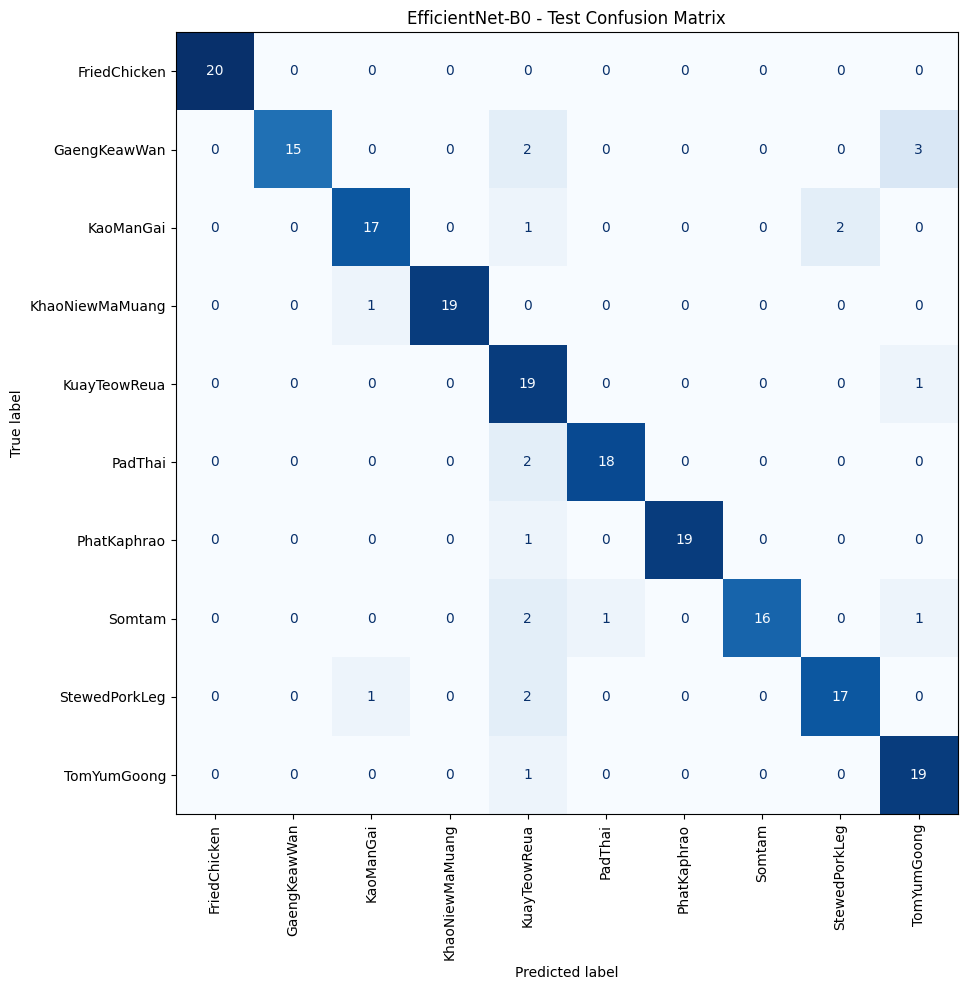

In [ ]:

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

labels_th = [
    class_to_thai[name]
    for name in class_names
]

y_true = results_df["ground_truth_th"].tolist()
y_pred = results_df["predicted_th"].tolist()

print("=== EfficientNet-B0 Test Report ===")

print(classification_report(
    y_true,
    y_pred,
    labels=labels_th,
    digits=4,
    zero_division=0
))

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=labels_th
)

fig, ax = plt.subplots(figsize=(12, 10))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=90,
    colorbar=False
)

plt.title("EfficientNet-B0 - Test Confusion Matrix")
plt.tight_layout()
plt.show()


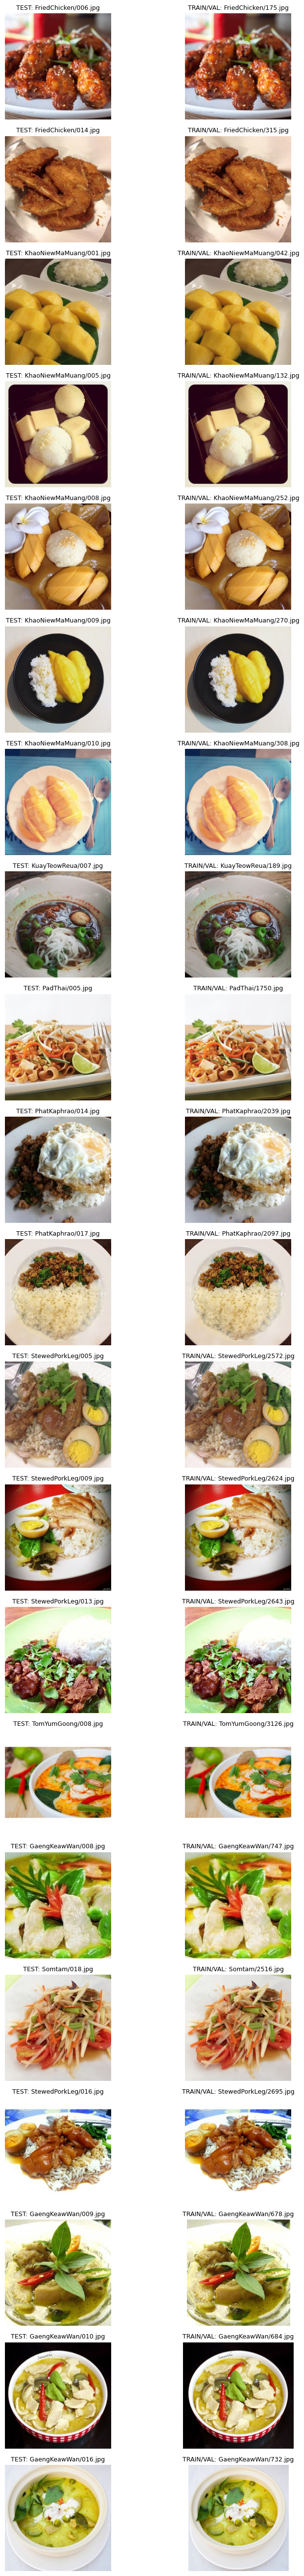

In [ ]:

import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
import math

pairs = sorted(
    suspects,
    key=lambda x: x["phash_distance"]
)

n = len(pairs)
fig, axes = plt.subplots(
    n, 2,
    figsize=(9, max(3, n * 2.5)),
    squeeze=False
)

for i, item in enumerate(pairs):
    paths = [
        Path(item["test_image"]),
        Path(item["closest_train_val"])
    ]

    for j, path in enumerate(paths):
        with Image.open(path) as img:
            axes[i, j].imshow(img.convert("RGB"))

        label = "TEST" if j == 0 else "TRAIN/VAL"
        axes[i, j].set_title(
            f"{label}: {path.parent.name}/{path.name}",
            fontsize=9
        )
        axes[i, j].axis("off")

    axes[i, 0].set_ylabel(
        f"Pair {i+1}\npHash={item['phash_distance']}",
        rotation=0,
        labelpad=45,
        fontsize=9
    )

plt.tight_layout()
plt.show()


In [ ]:

from pathlib import Path
from PIL import Image
import imagehash
import shutil
import hashlib

source = Path("/content/THFOOD10_fixed/THFOOD10")
test_dir = Path("/content/test_200")
clean_dir = Path("/content/THFOOD10_clean")

extensions = {".jpg", ".jpeg", ".png", ".webp"}

# ตรวจว่าข้อมูลยังอยู่ครบ
assert (source / "train").is_dir()
assert (source / "val").is_dir()
assert len(test_images) == 200

def phash_image(path):
    with Image.open(path) as img:
        return imagehash.phash(img.convert("RGB"))

# คำนวณ Hash ภาพ Test
test_hashes = [phash_image(p) for p in test_images]

# สร้างชุดข้อมูลใหม่
if clean_dir.exists():
    shutil.rmtree(clean_dir)

removed = []
kept = 0

for split in ["train", "val"]:
    for class_dir in sorted((source / split).iterdir()):
        if not class_dir.is_dir():
            continue

        destination = clean_dir / split / class_dir.name
        destination.mkdir(parents=True, exist_ok=True)

        for image_path in class_dir.rglob("*"):
            if (
                not image_path.is_file()
                or image_path.suffix.lower() not in extensions
            ):
                continue

            image_hash = phash_image(image_path)

            # <= 5 คือภาพน่าสงสัยว่าซ้ำ
            min_distance = min(
                image_hash - test_hash
                for test_hash in test_hashes
            )

            if min_distance <= 5:
                removed.append({
                    "split": split,
                    "class": class_dir.name,
                    "image": str(image_path),
                    "phash_distance": min_distance
                })
            else:
                relative_path = image_path.relative_to(class_dir)
                target = destination / relative_path
                target.parent.mkdir(parents=True, exist_ok=True)
                shutil.copy2(image_path, target)
                kept += 1

print("=== Clean Dataset ===")
print("Kept:", kept)
print("Excluded suspicious images:", len(removed))
print("Clean dataset:", clean_dir)

for split in ["train", "val"]:
    count = sum(
        1 for p in (clean_dir / split).rglob("*")
        if p.is_file() and p.suffix.lower() in extensions
    )
    print(split, count)


=== Clean Dataset ===
Kept: 2833
Excluded suspicious images: 21
Clean dataset: /content/THFOOD10_clean
train 2563
val 270


In [ ]:

import torch
from pathlib import Path
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

clean_dir = Path("/content/THFOOD10_clean")

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.75, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

val_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

train_dataset = datasets.ImageFolder(
    clean_dir / "train", transform=train_transform
)
val_dataset = datasets.ImageFolder(
    clean_dir / "val", transform=val_transform
)

assert train_dataset.class_to_idx == val_dataset.class_to_idx
assert len(train_dataset.classes) == 10
assert len(train_dataset) == 2563
assert len(val_dataset) == 270

class_names = train_dataset.classes

train_loader = DataLoader(
    train_dataset, batch_size=32, shuffle=True,
    num_workers=2, pin_memory=True
)
val_loader = DataLoader(
    val_dataset, batch_size=32, shuffle=False,
    num_workers=2, pin_memory=True
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Classes:", class_names)


Device: cuda
Train: 2563
Validation: 270
Classes: ['FriedChicken', 'GaengKeawWan', 'KaoManGai', 'KhaoNiewMaMuang', 'KuayTeowReua', 'PadThai', 'PhatKaphrao', 'Somtam', 'StewedPorkLeg', 'TomYumGoong']


In [ ]:

import torch.nn as nn
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

# เริ่มจาก Pretrained ImageNet ไม่ใช่โมเดลที่ฝึกครั้งก่อน
model = efficientnet_b0(
    weights=EfficientNet_B0_Weights.DEFAULT
)

for param in model.features.parameters():
    param.requires_grad = False

in_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(in_features, 10)

model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(
    model.classifier.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

print("Fresh EfficientNet-B0 ready")


Fresh EfficientNet-B0 ready


In [ ]:

import json
from pathlib import Path

save_dir = Path("/content/drive/MyDrive/Nouriva-AI/models")
save_dir.mkdir(parents=True, exist_ok=True)

best_acc = -1.0
bad_epochs = 0
patience = 3
max_epochs = 10
history_clean = []

for epoch in range(max_epochs):

    model.train()
    model.features.eval()

    train_correct = 0
    train_loss = 0.0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()

    model.eval()

    val_correct = 0
    val_loss = 0.0

    with torch.inference_mode():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()

    train_acc = train_correct / len(train_dataset)
    val_acc = val_correct / len(val_dataset)

    history_clean.append({
        "epoch": epoch + 1,
        "train_accuracy": train_acc,
        "val_accuracy": val_acc,
        "train_loss": train_loss / len(train_dataset),
        "val_loss": val_loss / len(val_dataset)
    })

    print(
        f"Epoch {epoch+1}/{max_epochs} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Val Loss: {val_loss / len(val_dataset):.4f}"
    )

    if val_acc > best_acc:
        best_acc = val_acc
        bad_epochs = 0

        torch.save({
            "model_state_dict": model.state_dict(),
            "class_names": class_names,
            "architecture": "efficientnet_b0",
            "epoch": epoch + 1,
            "val_accuracy": val_acc
        }, save_dir / "best_model_clean.pth")

        print("  ✓ Saved best_model_clean.pth")

    else:
        bad_epochs += 1

    if bad_epochs >= patience:
        print("Early stopping")
        break

with open(save_dir / "training_history_clean.json", "w") as f:
    json.dump(history_clean, f, indent=2)

print("\nTraining complete!")
print(f"Best Validation Accuracy: {best_acc:.2%}")
print("Model:", save_dir / "best_model_clean.pth")


Epoch 1/10 | Train Acc: 0.7690 | Val Acc: 0.8889 | Val Loss: 0.4870
  ✓ Saved best_model_clean.pth
Epoch 2/10 | Train Acc: 0.9313 | Val Acc: 0.9333 | Val Loss: 0.3224
  ✓ Saved best_model_clean.pth
Epoch 3/10 | Train Acc: 0.9481 | Val Acc: 0.9444 | Val Loss: 0.2524
  ✓ Saved best_model_clean.pth
Epoch 4/10 | Train Acc: 0.9567 | Val Acc: 0.9370 | Val Loss: 0.2364
Epoch 5/10 | Train Acc: 0.9649 | Val Acc: 0.9481 | Val Loss: 0.2017
  ✓ Saved best_model_clean.pth
Epoch 6/10 | Train Acc: 0.9692 | Val Acc: 0.9407 | Val Loss: 0.1912
Epoch 7/10 | Train Acc: 0.9727 | Val Acc: 0.9407 | Val Loss: 0.1814
Epoch 8/10 | Train Acc: 0.9688 | Val Acc: 0.9556 | Val Loss: 0.1679
  ✓ Saved best_model_clean.pth
Epoch 9/10 | Train Acc: 0.9782 | Val Acc: 0.9519 | Val Loss: 0.1698
Epoch 10/10 | Train Acc: 0.9809 | Val Acc: 0.9593 | Val Loss: 0.1628
  ✓ Saved best_model_clean.pth

Training complete!
Best Validation Accuracy: 95.93%
Model: /content/drive/MyDrive/Nouriva-AI/models/best_model_clean.pth


In [ ]:

import torch
import torch.nn as nn
import pandas as pd
from pathlib import Path
from PIL import Image
from torchvision.models import efficientnet_b0
from torchvision import transforms
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# โหลดโมเดล Clean ที่ฝึกเสร็จแล้ว
checkpoint_path = Path(
    "/content/drive/MyDrive/Nouriva-AI/models/best_model_clean.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

class_names = checkpoint["class_names"]

model = efficientnet_b0(weights=None)
model.classifier[1] = nn.Linear(
    model.classifier[1].in_features,
    len(class_names)
)
model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(device)
model.eval()

# Mapping ให้ตรงกับ Ground Truth
class_to_thai = {
    "FriedChicken": "ไก่ทอด",
    "GaengKeawWan": "แกงเขียวหวาน",
    "KaoManGai": "ข้าวมันไก่",
    "KhaoNiewMaMuang": "ข้าวเหนียวมะม่วง",
    "KuayTeowReua": "ก๋วยเตี๋ยวเรือ",
    "PadThai": "ผัดไทย",
    "PhatKaphrao": "ผัดกะเพรา",
    "Somtam": "ส้มตำ",
    "StewedPorkLeg": "ข้าวขาหมู",
    "TomYumGoong": "ต้มยำกุ้ง"
}

test_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

# Test Set เดิม 200 ภาพ
test_dir = Path("/content/test_200")
records = pd.read_csv(
    test_dir / "ground_truth.csv",
    encoding="utf-8-sig"
)

assert len(records) == 200

results = []

with torch.inference_mode():
    for _, row in records.iterrows():
        image_path = test_dir / row["image_path"]

        with Image.open(image_path) as img:
            x = test_transform(
                img.convert("RGB")
            ).unsqueeze(0).to(device)

        logits = model(x)
        probs = torch.softmax(logits, dim=1)[0]

        pred_idx = int(probs.argmax().item())
        pred_class = class_names[pred_idx]
        pred_th = class_to_thai[pred_class]
        true_th = str(row["ground_truth_th"]).strip()

        results.append({
            "image_path": row["image_path"],
            "ground_truth_th": true_th,
            "predicted_class": pred_class,
            "predicted_th": pred_th,
            "confidence": float(probs[pred_idx].item()),
            "correct": int(pred_th == true_th)
        })

results_df_clean = pd.DataFrame(results)

accuracy = accuracy_score(
    results_df_clean["ground_truth_th"],
    results_df_clean["predicted_th"]
)

macro_f1 = f1_score(
    results_df_clean["ground_truth_th"],
    results_df_clean["predicted_th"],
    average="macro",
    zero_division=0
)

save_dir = Path("/content/drive/MyDrive/Nouriva-AI/results")
save_dir.mkdir(parents=True, exist_ok=True)

output_path = save_dir / "efficientnet_clean_predictions.csv"
results_df_clean.to_csv(
    output_path, index=False, encoding="utf-8-sig"
)

print("=== CLEAN MODEL TEST RESULTS ===")
print("Test images:", len(results_df_clean))
print("Correct:", results_df_clean["correct"].sum())
print(f"Accuracy: {accuracy:.2%}")
print(f"Macro F1: {macro_f1:.2%}")
print("Saved:", output_path)

print("\n=== Classification Report ===")
print(classification_report(
    results_df_clean["ground_truth_th"],
    results_df_clean["predicted_th"],
    zero_division=0
))


=== CLEAN MODEL TEST RESULTS ===
Test images: 200
Correct: 184
Accuracy: 92.00%
Macro F1: 91.98%
Saved: /content/drive/MyDrive/Nouriva-AI/results/efficientnet_clean_predictions.csv

=== Classification Report ===
                  precision    recall  f1-score   support

  ก๋วยเตี๋ยวเรือ       0.85      0.85      0.85        20
       ข้าวขาหมู       0.90      0.95      0.93        20
      ข้าวมันไก่       0.90      0.90      0.90        20
ข้าวเหนียวมะม่วง       1.00      0.95      0.97        20
       ต้มยำกุ้ง       0.80      1.00      0.89        20
       ผัดกะเพรา       0.95      1.00      0.98        20
          ผัดไทย       0.94      0.85      0.89        20
           ส้มตำ       0.95      0.90      0.92        20
    แกงเขียวหวาน       1.00      0.80      0.89        20
          ไก่ทอด       0.95      1.00      0.98        20

        accuracy                           0.92       200
       macro avg       0.93      0.92      0.92       200
    weighted avg       0.93     